Task 1: Multi-Class Benchmark Classification Pipeline (Iris Dataset)
Internship: Datheon — Machine Learning & Data Science
Objective: Build and compare Logistic Regression and Decision Tree classifiers using the Iris dataset.

1. Import libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

2. Load the Iris dataset

In [4]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df = df.rename(columns={"target": "species_id"})
df["species"] = df["species_id"].map(dict(enumerate(iris.target_names)))

print("Dataset shape:", df.shape)
display(df.head())
print("\\nClass counts:")
display(df["species"].value_counts())

Dataset shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


\nClass counts:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

3. Explore and visualize the data

In [5]:
print("Missing values per column:")
display(df.isnull().sum())

print("\\nSummary statistics:")
display(df.describe())

Missing values per column:


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species_id           0
species              0
dtype: int64

\nSummary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


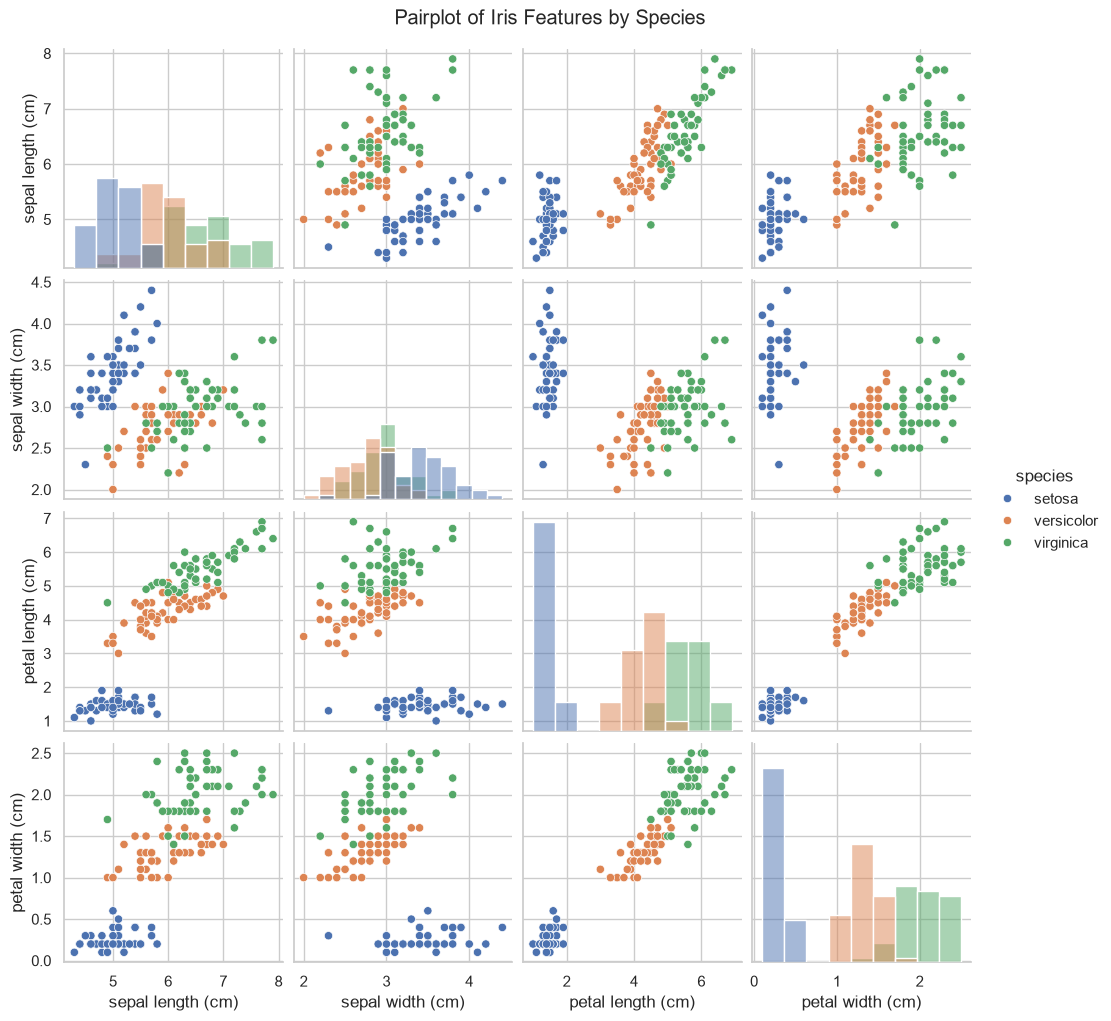

In [6]:
# Pairplot: relationships between flower measurements
sns.pairplot(df, vars=iris.feature_names, hue="species", diag_kind="hist")
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

4. Prepare features and split the data

In [7]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


5. Build and train both models

In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=4))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete


6. Evaluate and compare the models

In [9]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

for name, y_pred in predictions.items():
    print(f"\\nClassification report — {name}")
    print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


\nClassification report — Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

\nClassification report — Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



7. Plot confusion matrices

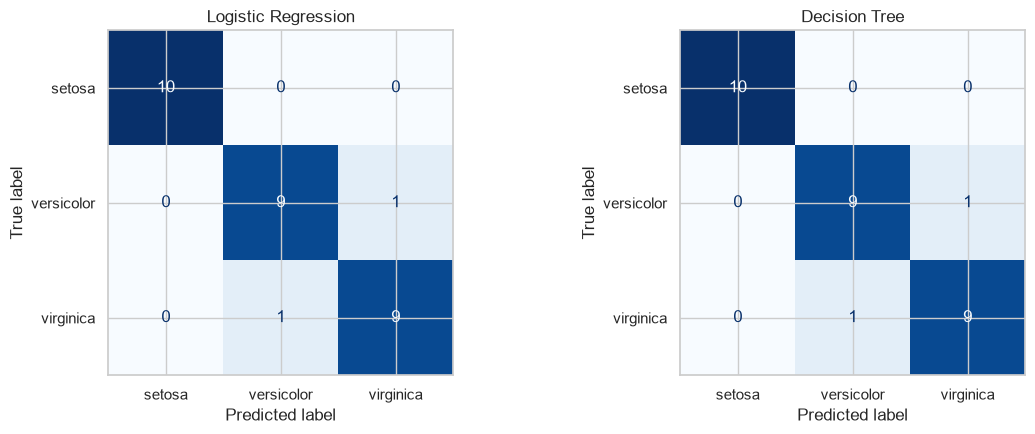

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

8. Compare metric scores visually

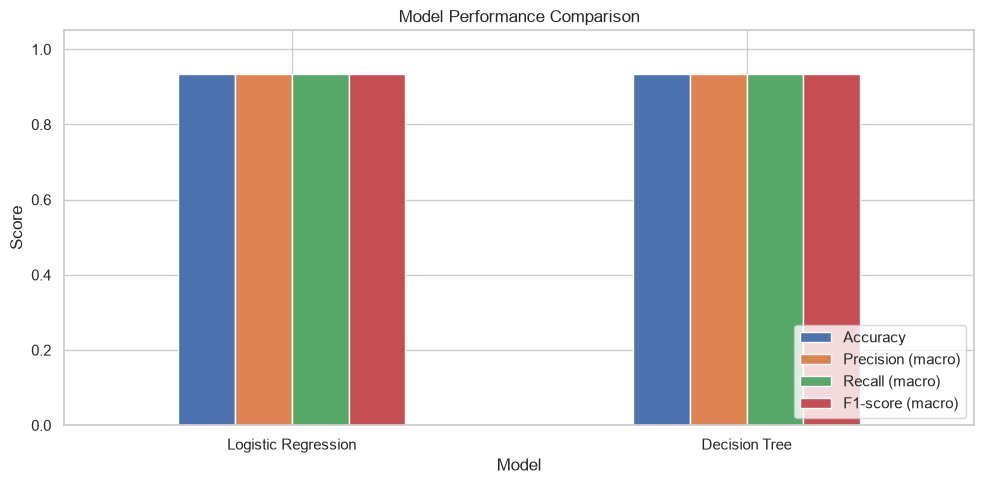

In [11]:
results_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

9. Decision-boundary visualization

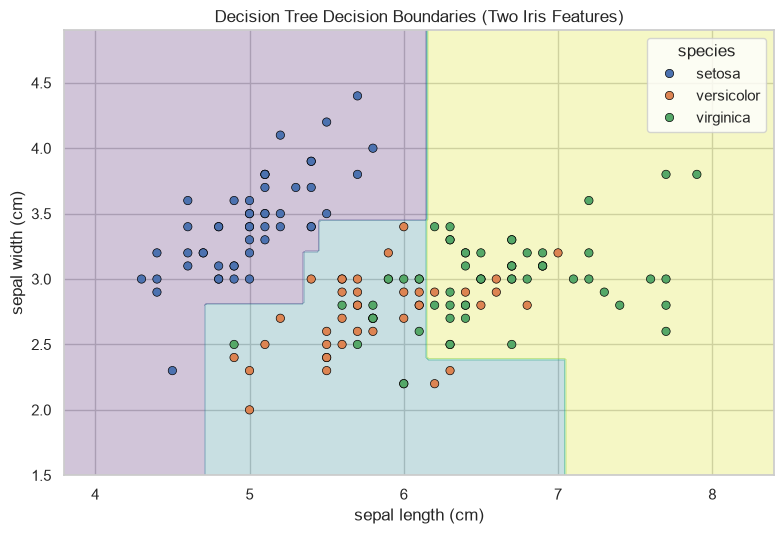

In [12]:
X_2d = iris.data[["sepal length (cm)", "sepal width (cm)"]]
y_2d = iris.target

tree_2d = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=4)
tree_2d.fit(X_2d, y_2d)

x_min, x_max = X_2d.iloc[:, 0].min() - 0.5, X_2d.iloc[:, 0].max() + 0.5
y_min, y_max = X_2d.iloc[:, 1].min() - 0.5, X_2d.iloc[:, 1].max() + 0.5
xx, yy = __import__("numpy").meshgrid(
    __import__("numpy").arange(x_min, x_max, 0.02),
    __import__("numpy").arange(y_min, y_max, 0.02)
)

grid = pd.DataFrame({
    "sepal length (cm)": xx.ravel(),
    "sepal width (cm)": yy.ravel()
})
Z = tree_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 5.5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
sns.scatterplot(
    data=df, x="sepal length (cm)", y="sepal width (cm)",
    hue="species", palette="deep", edgecolor="black"
)
plt.title("Decision Tree Decision Boundaries (Two Iris Features)")
plt.tight_layout()
plt.show()

10. Conclusion
After running the notebook, use the metric table and classification reports above to describe which model performed better on this test split. Do not assume one model is always best; base your conclusion on your actual results.

Example conclusion template:
In this project, I built and evaluated Logistic Regression and Decision Tree classifiers on the Iris dataset. I split the data into training and testing sets in an 80:20 ratio. For Logistic Regression, I used feature standardization with StandardScaler. I compared the models using accuracy, macro precision, macro recall, and macro F1-score, and visualized their predictions using confusion matrices. Based on the test results, [write which model performed better and include the scores from your results table].